# Guide pour l'Appel à une API Hugging Face pour la Segmentation d'Images

Bienvenue ! Ce notebook a pour but de vous guider pas à pas dans l'utilisation de l'API d'inférence de Hugging Face pour effectuer de la segmentation d'images. La segmentation d'images consiste à attribuer une étiquette (comme "cheveux", "vêtement", "arrière-plan") à chaque pixel d'une image.

Nous allons :
1. Comprendre ce qu'est une API et comment s'y connecter.
2. Envoyer une image à un modèle de segmentation hébergé sur Hugging Face.
3. Récupérer et interpréter les résultats.
4. Visualiser les masques de segmentation.
5. Étendre cela pour traiter plusieurs images.

## 1. Configuration Initiale et Importations

Commençons par importer les bibliothèques Python nécessaires. Nous aurons besoin de :
- `os` pour interagir avec le système de fichiers (lister les images).
- `requests` pour effectuer des requêtes HTTP vers l'API.
- `PIL (Pillow)` pour manipuler les images.
- `matplotlib.pyplot` pour afficher les images et les masques.
- `numpy` pour la manipulation des tableaux (les images sont des tableaux de pixels).
- `tqdm.notebook` pour afficher une barre de progression (utile pour plusieurs images).
- `base64` et `io` pour décoder les masques renvoyés par l'API.

In [32]:
import os
import requests
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
from tqdm.notebook import tqdm
import base64
import io

### Variables de Configuration

Nous devons définir quelques variables :
- `image_dir`: Le chemin vers le dossier contenant vos images. **Assurez-vous de modifier ce chemin si nécessaire.**
- `max_images`: Le nombre maximum d'images à traiter (pour ne pas surcharger l'API ou attendre trop longtemps).
- `api_token`: Votre jeton d'API Hugging Face. **IMPORTANT : Gardez ce jeton secret !**

**Comment obtenir un token API Hugging Face ?**
1. Créez un compte sur [huggingface.co](https://huggingface.co/).
2. Allez dans votre profil -> Settings -> Access Tokens.
3. Créez un nouveau token (par exemple, avec le rôle "read").
4. Copiez ce token ici.

In [ ]:
from dotenv import load_dotenv

# --- Paramètres de l'analyse ---
# Dossier contenant les images à segmenter (chemin relatif à la racine du projet)
image_dir = "assets/top_influenceurs_2024/IMG"

# Nombre maximum d'images envoyées à l'API : on reste bas pendant les tests
# pour limiter le temps d'attente et le coût des appels
max_images = 3  # Commençons avec peu d'images

# --- Chargement du token API ---
# load_dotenv() lit le fichier .env et place ses variables dans l'environnement.
# Le token n'est ainsi jamais écrit en dur dans le code (le .env est exclu de Git).
load_dotenv()
api_token = os.getenv("HF_TOKEN") # Renvoie None si la variable est absente

# --- Vérifications avant de continuer ---
# On s'assure que le dossier d'images existe et on affiche le nombre de fichiers
if os.path.exists(image_dir):
    print(f"Dossier '{image_dir}' trouvé : {len(os.listdir(image_dir))} fichiers.")
else:
    print(f"Dossier '{image_dir}' introuvable, vérifie le chemin.")

# On confirme que le token a été chargé, sans jamais l'afficher
if api_token:
    print("Token chargé depuis le .env.")
else:
    print("ATTENTION : HF_TOKEN introuvable dans le fichier .env.")

Dossier 'assets/top_influenceurs_2024/IMG' trouvé : 50 fichiers.
Token chargé depuis le .env.


## 2. Comprendre l'API d'Inférence Hugging Face

L'API d'inférence permet d'utiliser des modèles hébergés sur Hugging Face sans avoir à les télécharger ou à gérer l'infrastructure.

- **Modèle utilisé** : Nous allons utiliser le modèle `sayeed99/segformer_b3_clothes`, spécialisé dans la segmentation de vêtements et de parties du corps.
- **URL de l'API** : L'URL pour un modèle est généralement `https://api-inference.huggingface.co/models/NOM_DU_MODELE`.
- **Headers (En-têtes)** : Pour s'authentifier et spécifier le type de contenu, nous envoyons des en-têtes avec notre requête.
    - `Authorization`: Contient notre token API (précédé de `Bearer `).
    - `Content-Type`: Indique que nous envoyons une image au format JPEG (ou PNG selon le cas).

In [ ]:
# --- Configuration de l'API Hugging Face ---
# Endpoint serverless du modèle segformer_b3_clothes, via le fournisseur "hf-inference"
API_URL = "https://router.huggingface.co/hf-inference/models/sayeed99/segformer_b3_clothes"

# En-tête d'authentification : le token est envoyé au format "Bearer <token>"
headers = {
    "Authorization": f"Bearer {api_token}"
    # Le "Content-Type" sera ajouté lors de l'envoi de l'image
}

# --- Construction de la liste des images à traiter ---
image_paths = []
# sorted() trie les fichiers par ordre alphabétique pour un traitement reproductible
for nom in sorted(os.listdir(image_dir)):
    # On ne garde que les fichiers image (et on ignore les fichiers cachés comme .DS_Store).
    # .lower() permet d'accepter aussi les extensions en majuscules (.PNG, .JPG)
    if nom.lower().endswith((".png", ".jpg", ".jpeg")):
        # os.path.join assemble le dossier et le nom en un chemin complet
        image_paths.append(os.path.join(image_dir, nom))

# On limite la liste aux max_images premières images pour les tests
image_paths = image_paths[:max_images]

# Affichage de contrôle
if not image_paths:
    print(f"Aucune image trouvée dans '{image_dir}'. Veuillez y ajouter des images.")
else:
    print(f"{len(image_paths)} image(s) à traiter : {image_paths}")

3 image(s) à traiter : ['assets/top_influenceurs_2024/IMG/image_0.png', 'assets/top_influenceurs_2024/IMG/image_1.png', 'assets/top_influenceurs_2024/IMG/image_10.png']


## 3. Fonctions Utilitaires pour le Traitement des Masques

Le modèle que nous utilisons (`sayeed99/segformer_b3_clothes`) renvoie des masques pour différentes classes (cheveux, chapeau, etc.). Ces masques sont encodés en base64. Les fonctions ci-dessous sont fournies pour vous aider à :
1.  `CLASS_MAPPING`: Un dictionnaire qui associe les noms de classes (ex: "Hat") à des identifiants numériques.
2.  `get_image_dimensions`: Récupérer les dimensions d'une image.
3.  `decode_base64_mask`: Décoder un masque de base64 en une image (tableau NumPy) et le redimensionner.
4.  `create_masks`: Combiner les masques de toutes les classes détectées en un seul masque de segmentation final, où chaque pixel a la valeur de l'ID de sa classe.

**Cette partie est donnée car elle est spécifique au format de sortie de ce modèle et un peu complexe pour une première approche.** Lisez-la pour comprendre son rôle, mais ne vous attardez pas sur les détails d'implémentation pour l'instant.

In [35]:
CLASS_MAPPING = {
    "Background": 0,
    "Hat": 1,
    "Hair": 2,
    "Sunglasses": 3,
    "Upper-clothes": 4,
    "Skirt": 5,
    "Pants": 6,
    "Dress": 7,
    "Belt": 8,
    "Left-shoe": 9,
    "Right-shoe": 10,
    "Face": 11,
    "Left-leg": 12,
    "Right-leg": 13,
    "Left-arm": 14,
    "Right-arm": 15,
    "Bag": 16,
    "Scarf": 17
}

def get_image_dimensions(img_path):
    """
    Get the dimensions of an image.

    Args:
        img_path (str): Path to the image.

    Returns:
        tuple: (width, height) of the image.
    """
    original_image = Image.open(img_path)
    return original_image.size

def decode_base64_mask(base64_string, width, height):
    """
    Decode a base64-encoded mask into a NumPy array.

    Args:
        base64_string (str): Base64-encoded mask.
        width (int): Target width.
        height (int): Target height.

    Returns:
        np.ndarray: Single-channel mask array.
    """
    mask_data = base64.b64decode(base64_string)
    mask_image = Image.open(io.BytesIO(mask_data))
    mask_array = np.array(mask_image)
    if len(mask_array.shape) == 3:
        mask_array = mask_array[:, :, 0]  # Take first channel if RGB
    mask_image = Image.fromarray(mask_array).resize((width, height), Image.NEAREST)
    return np.array(mask_image)

def create_masks(results, width, height):
    """
    Combine multiple class masks into a single segmentation mask.

    Args:
        results (list): List of dictionaries with 'label' and 'mask' keys.
        width (int): Target width.
        height (int): Target height.

    Returns:
        np.ndarray: Combined segmentation mask with class indices.
    """
    combined_mask = np.zeros((height, width), dtype=np.uint8)  # Initialize with Background (0)

    # Process non-Background masks first
    for result in results:
        label = result['label']
        class_id = CLASS_MAPPING.get(label, 0)
        if class_id == 0:  # Skip Background
            continue
        mask_array = decode_base64_mask(result['mask'], width, height)
        combined_mask[mask_array > 0] = class_id

    # Process Background last to ensure it doesn't overwrite other classes unnecessarily
    # (Though the model usually provides non-overlapping masks for distinct classes other than background)
    for result in results:
        if result['label'] == 'Background':
            mask_array = decode_base64_mask(result['mask'], width, height)
            # Apply background only where no other class has been assigned yet
            # This logic might need adjustment based on how the model defines 'Background'
            # For this model, it seems safer to just let non-background overwrite it first.
            # A simple application like this should be fine: if Background mask says pixel is BG, set it to 0.
            # However, a more robust way might be to only set to background if combined_mask is still 0 (initial value)
            combined_mask[mask_array > 0] = 0 # Class ID for Background is 0

    return combined_mask

## 4. Segmentation d'une Seule Image

Avant de traiter toutes les images, concentrons-nous sur une seule pour bien comprendre le processus.

Étapes :
1.  Choisir une image.
2.  Ouvrir l'image en mode binaire (`"rb"`) et lire son contenu (`data`).
3.  Déterminer le `Content-Type` (par exemple, `"image/jpeg"` ou `"image/png"`).
4.  Envoyer la requête POST à l'API avec `requests.post()` en passant l'URL, les headers et les données.
5.  Vérifier le code de statut de la réponse. Une erreur sera levée si le code n'est pas 2xx (succès) grâce à `response.raise_for_status()`.
6.  Convertir la réponse JSON en un dictionnaire Python avec `response.json()`.
7.  Utiliser nos fonctions `get_image_dimensions` et `create_masks` pour obtenir le masque final.
8.  Afficher l'image originale et le masque segmenté.

In [36]:
if image_paths:
    # Étape 1 : on teste le processus sur la première image de la liste
    single_image_path = image_paths[0] # Prenons la première image de notre liste
    print(f"Traitement de l'image : {single_image_path}")

    # Le bloc try/except intercepte toute erreur (fichier, réseau, API)
    # pour afficher un message clair au lieu de faire planter le notebook
    try:
        # Étape 2 : lecture de l'image en mode binaire ("rb" = read binary).
        # Le "with" referme automatiquement le fichier après la lecture.
        with open(single_image_path, "rb") as f:
            image_data = f.read()
       
        # Étapes 3 et 4 : envoi de l'image à l'API via une requête POST
        # - Content-Type indique le format de l'image (nos images sont des PNG)
        # - **headers ajoute l'en-tête d'authentification défini plus haut
        # - data contient l'image brute (octets)
        # - timeout limite l'attente à 60 secondes si le serveur ne répond pas
        response = requests.post(API_URL, headers={"Content-Type": "image/png", **headers}, data=image_data, timeout=60)  

        # Étape 5 : déclenche une erreur si le code HTTP n'est pas un succès (2xx),
        # par exemple 401 (token invalide), 402 (crédits épuisés) ou 503 (modèle indisponible)
        response.raise_for_status()  

        # Étape 6 : conversion de la réponse JSON en liste Python.
        # Chaque élément contient un "label" (ex. "Hair"), un "score" et un "mask" en base64
        results = response.json()

        # Étape 7 : création du masque final
        # On récupère la taille de l'image d'origine pour que le masque ait les mêmes dimensions
        width, height = get_image_dimensions(single_image_path)
        # create_masks fusionne les masques de chaque classe en un seul tableau
        # où chaque pixel contient l'identifiant de sa classe (0 = fond, 4 = haut, etc.)
        mask = create_masks(results, width, height)
        print(f"Masque créé avec succès pour l'image : {single_image_path}")
       
        # Étape 8 : affichage côte à côte de l'image originale et du masque
        fig, ax = plt.subplots(1, 2, figsize=(12, 6)) # 1 ligne, 2 colonnes

        # À gauche : la photo d'origine
        ax[0].imshow(Image.open(single_image_path)) 
        ax[0].set_title("Image originale")
        ax[0].axis('off') # Masque les graduations des axes

        # À droite : le masque de segmentation
        # - cmap="tab20" : palette de couleurs bien distinctes, adaptée aux catégories
        # - vmin/vmax : chaque classe (0 à 17) garde toujours la même couleur d'une image à l'autre
        # - interpolation="nearest" : évite le lissage qui créerait de fausses couleurs entre deux classes
        ax[1].imshow(mask, cmap='tab20', vmin=0, vmax=17, interpolation='nearest')  # Using 'tab20' colormap for better visualization
        ax[1].set_title("Masque de segmentation")
        ax[1].axis('off')
        plt.show()

    except Exception as e:
        # Affiche la nature de l'erreur pour faciliter le diagnostic
        print(f"Une erreur est survenue : {e}")
else:
    print("Aucune image à traiter. Vérifiez la configuration de 'image_dir' et 'max_images'.")

Traitement de l'image : assets/top_influenceurs_2024/IMG/image_0.png
Une erreur est survenue : 402 Client Error: Payment Required for url: https://router.huggingface.co/hf-inference/models/sayeed99/segformer_b3_clothes


## 5. Segmentation de Plusieurs Images (Batch)

Maintenant que nous savons comment traiter une image, nous pouvons créer une fonction pour en traiter plusieurs.
Cette fonction va boucler sur la liste `image_paths` et appliquer la logique de segmentation à chaque image.
Nous utiliserons `tqdm` pour avoir une barre de progression.

In [37]:
import time # Module de la bibliothèque standard, utilisé pour faire des pauses

def segment_images_batch(list_of_image_paths):
  
    batch_segmentations = [] # Accueillera un masque (ou None) par image

     # Parcours de chaque image ; tqdm affiche une barre de progression
    for img_path in tqdm(list_of_image_paths, desc="Segmentation en batch"):
        # Le try/except est placé DANS la boucle : si une image échoue,
        # on passe à la suivante au lieu d'arrêter tout le traitement
        try:
            # Lecture de l'image en binaire
            with open(img_path, "rb") as f:
                image_data = f.read()
            # Envoi de l'image à l'API (format PNG, délai maximum de 60 secondes)
            response = requests.post(API_URL, headers={"Content-Type": "image/png", **headers}, data=image_data, timeout=60)
            
            # Déclenche une erreur si l'API ne renvoie pas un succès (2xx)
            response.raise_for_status()
            
            # Conversion de la réponse JSON en liste de résultats (label, score, mask)
            results = response.json()
            
            # Fusion des masques en un masque unique aux dimensions de l'image
            width, height = get_image_dimensions(img_path)
            mask = create_masks(results, width, height)
            batch_segmentations.append(mask)
       
        except Exception as e:
            # En cas d'échec, on affiche l'erreur et on ajoute None à la place du masque.
            # Ainsi, la liste des masques garde le même ordre que la liste des images :
            # le masque n°i correspond toujours à l'image n°i.
            print(f"Erreur lors du traitement de {img_path}: {e}")
            batch_segmentations.append(None)
        
        # Pause d'une seconde entre deux appels, pour respecter les limites
        # de requêtes de l'API (sinon risque de blocage temporaire, erreur 429)
        time.sleep(1)  
    return batch_segmentations

# --- Lancement du traitement en batch ---
if image_paths:
    print(f"\nTraitement de {len(image_paths)} image(s) en batch...")
    batch_seg_results = segment_images_batch(image_paths)
    print("Traitement en batch terminé.")
else:
    batch_seg_results = []
    print("Aucune image à traiter en batch.")


Traitement de 3 image(s) en batch...


Segmentation en batch:   0%|          | 0/3 [00:00<?, ?it/s]

Erreur lors du traitement de assets/top_influenceurs_2024/IMG/image_0.png: 402 Client Error: Payment Required for url: https://router.huggingface.co/hf-inference/models/sayeed99/segformer_b3_clothes
Erreur lors du traitement de assets/top_influenceurs_2024/IMG/image_1.png: 402 Client Error: Payment Required for url: https://router.huggingface.co/hf-inference/models/sayeed99/segformer_b3_clothes
Erreur lors du traitement de assets/top_influenceurs_2024/IMG/image_10.png: 402 Client Error: Payment Required for url: https://router.huggingface.co/hf-inference/models/sayeed99/segformer_b3_clothes
Traitement en batch terminé.


## 6. Affichage des Résultats en Batch

Nous allons maintenant créer une fonction pour afficher les images originales et leurs segmentations correspondantes côte à côte, dans une grille.

In [38]:
def display_segmented_images_batch(original_image_paths, segmentation_masks):

    # zip() parcourt les deux listes en parallèle :
    # chaque image est associée au masque situé à la même position
    for img_path, mask in zip(original_image_paths, segmentation_masks):
        #On n'affiche que les images dont la segmentation a réussi
        if mask is not None:
            fig, ax = plt.subplots(1, 2, figsize=(12, 6)) # 1 ligne, 2 colonnes
            
            # À gauche : la photo d'origine
            ax[0].imshow(Image.open(img_path)) 
            ax[0].set_title("Image originale")
            ax[0].axis('off')
            
            # À droite : le masque, avec une couleur fixe par classe (0 à 17)
            ax[1].imshow(mask, cmap='tab20', vmin=0, vmax=17, interpolation='nearest') 
            ax[1].set_title("Masque de segmentation")
            ax[1].axis('off')

            plt.show()
        else:
            # L'image a échoué lors de la segmentation (voir les erreurs de la cellule précédente)
            print(f"Pas de masque disponible pour l'image : {img_path}")

# --- Affichage des résultats du batch ---
if batch_seg_results:
    display_segmented_images_batch(image_paths, batch_seg_results)
else:
    print("Aucun résultat de segmentation à afficher.")

Pas de masque disponible pour l'image : assets/top_influenceurs_2024/IMG/image_0.png
Pas de masque disponible pour l'image : assets/top_influenceurs_2024/IMG/image_1.png
Pas de masque disponible pour l'image : assets/top_influenceurs_2024/IMG/image_10.png


## Conclusion et Prochaines Étapes

Félicitations ! Vous avez appris à :
- Configurer les appels à l'API d'inférence Hugging Face.
- Envoyer des images pour la segmentation.
- Interpréter les résultats (avec l'aide des fonctions fournies).
- Visualiser les segmentations.

Pistes d'amélioration ou d'exploration :
- **Gestion d'erreurs plus fine** : Implémenter des tentatives multiples (retry) en cas d'échec de l'API (par exemple, si le modèle est en cours de chargement).
- **Appels asynchrones** : Pour un grand nombre d'images, des appels asynchrones (avec `asyncio` et `aiohttp`) seraient beaucoup plus rapides.
- **Autres modèles** : Explorer d'autres modèles de segmentation ou d'autres tâches sur Hugging Face Hub.

N'hésitez pas à modifier le code, à tester avec vos propres images et à explorer davantage !

**_Note_** : Si vous aimez ce modèle, n'hésitez pas à le [télécharger](https://huggingface.co/sayeed99/segformer_b3_clothes) et jouer avec directement sur votre machine !

## 7. Visualisation et analyse des résultats

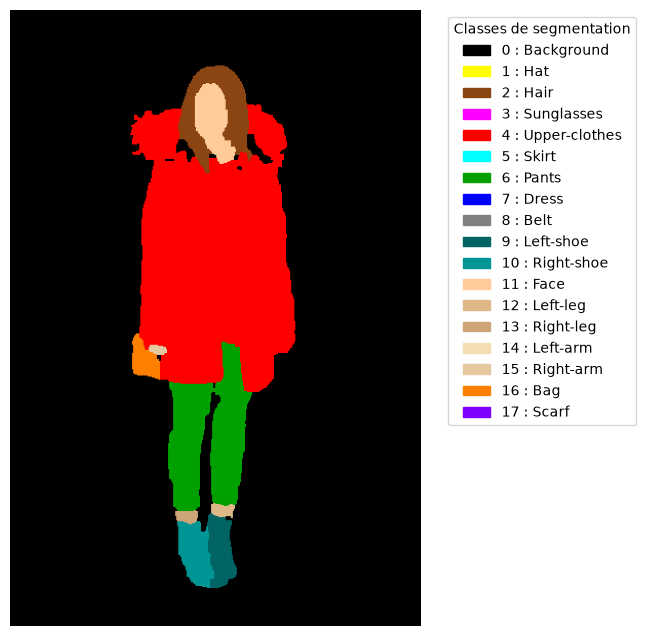

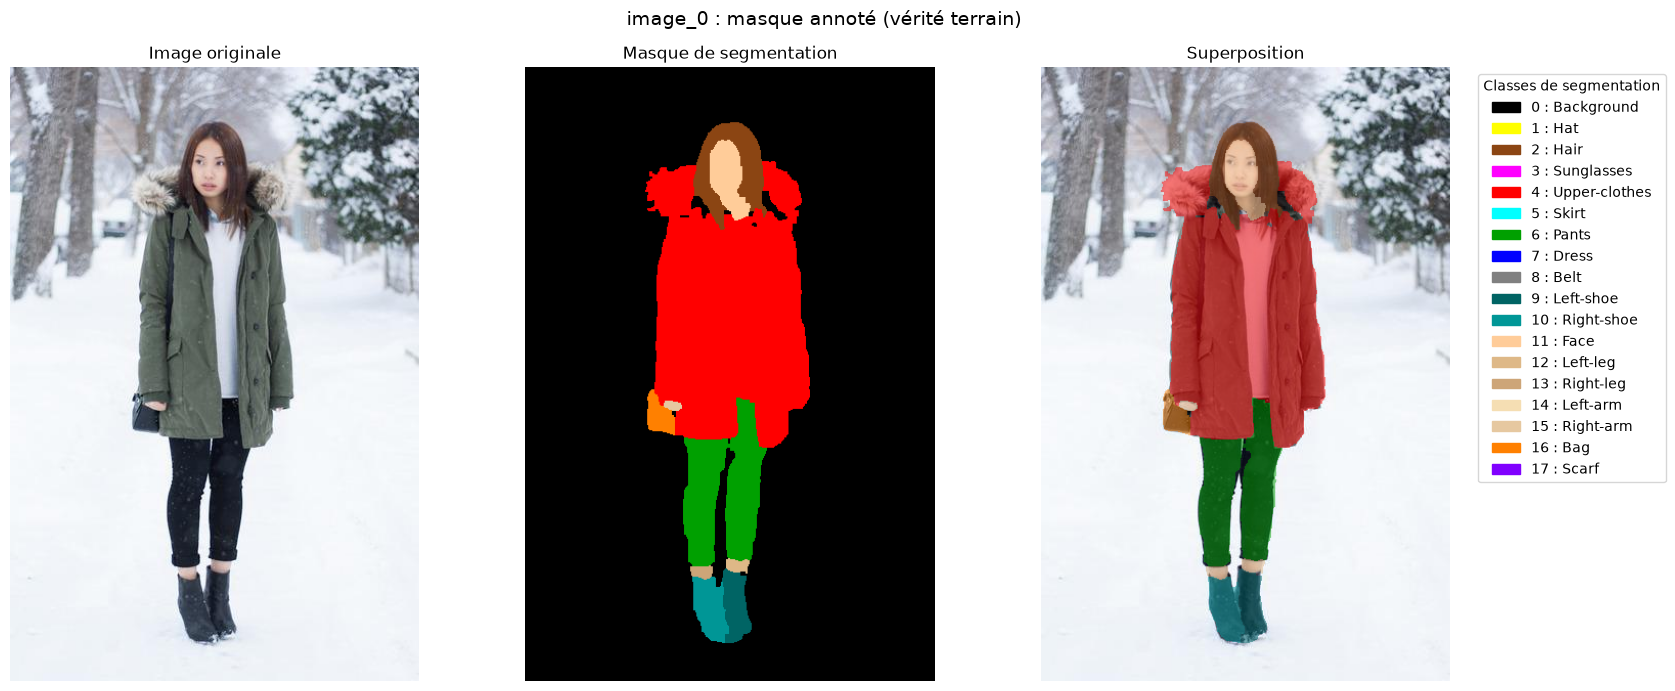

Background      IoU = 1.00
Hair            IoU = 1.00
Upper-clothes   IoU = 1.00
Pants           IoU = 1.00
Left-shoe       IoU = 1.00
Right-shoe      IoU = 1.00
Face            IoU = 1.00
Left-leg        IoU = 1.00
Right-leg       IoU = 1.00
Right-arm       IoU = 1.00
Bag             IoU = 1.00

mIoU (moyenne) = 1.00


In [ ]:
from matplotlib.patches import Patch

# --- Palette de couleurs personnalisée (RGB) ---
# Associe chaque numéro de classe du modèle (0 à 17) à une couleur unique.
# Choix de cohérence :
# - vêtements et accessoires en couleurs vives, pour qu'ils ressortent (ce qui intéresse les marques)
# - chaussures gauche/droite dans deux tons d'une même couleur (une paire = un même objet)
# - parties du corps dans des tons chair proches, pour rester discrètes
custom_colormap = {
    0: (0, 0, 0),         # - Arrière-plan
    1: (255, 255, 0),     # - Chapeau
    2: (139, 69, 19),     # - Cheveux
    3: (255, 0, 255),     # - Lunettes de soleil
    4: (255, 0, 0),       # - Haut (vêtement)
    5: (0, 255, 255),     # - Jupe
    6: (0, 160, 0),       # - Pantalon
    7: (0, 0, 255),       # - Robe
    8: (128, 128, 128),   # - Ceinture
    9: (0, 100, 100),      # - Chaussure gauche 
    10: (0, 150, 150),     # - Chaussure droite 
    11: (255, 204, 153),   # - Visage 
    12: (222, 184, 135),   # - Jambe gauche
    13: (205, 165, 120),   # - Jambe droite
    14: (245, 222, 179),   # - Bras gauche
    15: (230, 200, 160),   # - Bras droit
    16: (255, 128, 0),    # - Sac
    17: (128, 0, 255),    # - Écharpe
}

def colorize_mask(mask, colormap):

    """
    Transforme un masque de segmentation (un numéro de classe par pixel)
    en image couleur, à l'aide d'une palette.

    Args:
        mask (np.ndarray): Masque 2D (hauteur x largeur) contenant les numéros de classe.
        colormap (dict): Palette {numéro de classe: (R, G, B)}.

    Returns:
        np.ndarray: Image couleur 3D (hauteur x largeur x 3), valeurs de 0 à 255.
    """
    height, width = mask.shape

    # Image noire de la même taille que le masque, avec 3 canaux de couleur (R, G, B).
    # uint8 = entiers de 0 à 255, le format standard d'une image.
    color_mask = np.zeros((height, width, 3), dtype=np.uint8)

    # Pour chaque classe, on peint en une seule opération tous les pixels qui lui appartiennent.
    # (mask == class_id) est un tableau de booléens : True là où le pixel est de cette classe.
    for class_id, color in colormap.items():
        color_mask[mask == class_id] = color

    return color_mask

# --- Dictionnaire inverse : numéro de classe -> nom ---
# CLASS_MAPPING va dans le sens nom -> numéro (ex. "Pants" -> 6).
# On construit l'inverse une seule fois pour retrouver directement un nom (ex. 6 -> "Pants").
ID_TO_LABEL = {class_id: label for label, class_id in CLASS_MAPPING.items()}

# --- Éléments de la légende ---
# Un carré de couleur (Patch) par classe, avec son numéro et son nom.
# Patch attend des couleurs entre 0 et 1, alors que la palette va de 0 à 255 : on divise par 255.
legend_patches = [
    Patch(color=np.array(color) / 255, label=f"{class_id} : {ID_TO_LABEL[class_id]}")
    for class_id, color in custom_colormap.items()
]

# --- Test : affichage d'un masque annoté avec sa légende ---
annotated = np.array(Image.open("assets/top_influenceurs_2024/Mask/mask_0.png"))

plt.figure(figsize=(8, 8))
plt.imshow(colorize_mask(annotated, custom_colormap))
plt.axis("off") # Masque les graduations des axes
# Légende placée à droite de l'image (bbox_to_anchor) pour ne pas cacher la silhouette
plt.legend(handles=legend_patches, bbox_to_anchor=(1.05, 1), loc="upper left", title="Classes de segmentation") 
plt.show()

def display_segmentation(image_path, mask, title=None):

    """
    Affiche côte à côte une image, son masque de segmentation colorié
    et la superposition du masque sur l'image.

    Fonctionne aussi bien avec un masque annoté qu'avec un masque prédit par le modèle.

    Args:
        image_path (str): Chemin vers l'image originale.
        mask (np.ndarray): Masque de segmentation (un numéro de classe par pixel).
        title (str, optional): Titre général de la figure.
    """
    # Chargement de l'image, convertie en RGB (au cas où un fichier aurait
    # un 4e canal de transparence, ce qui ferait échouer le mélange des couleurs)
    image = np.array(Image.open(image_path).convert("RGB"))

    # Masque colorié avec la palette personnalisée
    colored_mask = colorize_mask(mask, custom_colormap)

    # --- Superposition ---
    # On part d'une copie de la photo pour ne pas modifier l'original
    overlay = image.copy()
    # True pour chaque pixel qui n'est pas du fond (classe 0)
    foreground = mask > 0 
    # Uniquement sur ces pixels : moyenne 50/50 entre la photo et la couleur de la classe.
    # Le fond garde ainsi la photo d'origine, sans être assombri.
    # astype(np.uint8) reconvertit le résultat (nombres à virgule) en entiers de 0 à 255.
    overlay[foreground] = (0.5 * image[foreground] + 0.5 * colored_mask[foreground]).astype(np.uint8)

    # --- Figure avec 3 zones côte à côte ---
    fig, ax = plt.subplots(1, 3, figsize=(18, 7))

    ax[0].imshow(image)
    ax[0].set_title("Image originale")

    ax[1].imshow(colored_mask)
    ax[1].set_title("Masque de segmentation")

    ax[2].imshow(overlay)
    ax[2].set_title("Superposition")

    # Masque les graduations sur les 3 zones
    for a in ax:
        a.axis("off")

    # Légende unique, placée à droite de la dernière image
    ax[2].legend(handles=legend_patches, bbox_to_anchor=(1.05, 1), loc="upper left",
                 title="Classes de segmentation")

    # Titre général, seulement s'il a été fourni
    if title:
        fig.suptitle(title, fontsize=14)

    plt.tight_layout() # Ajuste les marges pour éviter que titres, images et légende se chevauchent
    plt.show()

# --- Test avec la première image et son masque annoté ---
annotated = np.array(Image.open("assets/top_influenceurs_2024/Mask/mask_0.png"))
display_segmentation("assets/top_influenceurs_2024/IMG/image_0.png", annotated,
                     title="image_0 : masque annoté (vérité terrain)")

def compute_iou(pred_mask, true_mask, class_id):

    """
    Calcule l'IoU (Intersection over Union) d'une classe entre deux masques.

    IoU = pixels prédits ET annotés pour la classe / pixels prédits OU annotés pour la classe

    Args:
        pred_mask (np.ndarray): Masque prédit par le modèle.
        true_mask (np.ndarray): Masque annoté (vérité terrain).
        class_id (int): Numéro de la classe à évaluer.

    Returns:
        float: IoU entre 0 (aucun recouvrement) et 1 (recouvrement parfait),
               ou np.nan si la classe est absente des deux masques.
    """ 
    # Tableaux de booléens : True là où le pixel appartient à la classe
    pred = pred_mask == class_id
    true = true_mask == class_id

    # & = "et" pixel par pixel, | = "ou" pixel par pixel.
    # .sum() compte les True (True vaut 1, False vaut 0).
    intersection = (pred & true).sum()
    union = (pred | true).sum()

    # Classe absente des deux masques : rien à évaluer.
    # On renvoie np.nan ("pas de résultat") plutôt que 0, qui signifierait "erreur totale",
    # et on évite ainsi une division par zéro.
    if union == 0:
        return np.nan

    return intersection / union


def compute_iou_per_class(pred_mask, true_mask):

    """
    Calcule l'IoU de chaque classe présente dans au moins un des deux masques.

    Args:
        pred_mask (np.ndarray): Masque prédit par le modèle.
        true_mask (np.ndarray): Masque annoté (vérité terrain).

    Returns:
        dict: {nom de la classe: IoU}, sans les classes absentes des deux masques.
    """
    scores = {}
    for class_id in range(len(CLASS_MAPPING)):  # Classes 0 à 17
        iou = compute_iou(pred_mask, true_mask, class_id)
        # On ne garde que les classes réellement évaluables
        if not np.isnan(iou):
            scores[ID_TO_LABEL[class_id]] = iou
    return scores

# --- Test : masque annoté comparé à lui-même ---
# Deux masques identiques doivent donner un IoU de 1.00 pour chaque classe présente.
# Cela valide le calcul avant de l'utiliser sur les vraies prédictions du modèle.
annotated = np.array(Image.open("assets/top_influenceurs_2024/Mask/mask_0.png"))
scores = compute_iou_per_class(annotated, annotated)

# Affichage aligné : nom sur 15 caractères, IoU avec 2 décimales
for label, iou in scores.items():
    print(f"{label:<15} IoU = {iou:.2f}")
# mIoU : moyenne des IoU des classes présentes (score global de référence en segmentation)
print(f"\nmIoU (moyenne) = {np.mean(list(scores.values())):.2f}")

In [58]:
import random

# --- 1. Correspondance image -> masque annoté ---
def get_mask_path(image_path):
    """
    Renvoie le chemin du masque annoté associé à une image.
    Exemple : assets/.../IMG/image_12.png -> assets/.../Mask/mask_12.png
    """
    dataset_dir = os.path.dirname(os.path.dirname(image_path))  # Remonte au dossier top_influenceurs_2024
    filename = os.path.basename(image_path).replace("image_", "mask_")
    return os.path.join(dataset_dir, "Mask", filename)


# --- 2. Répartition validation / test ---
# On repart de toutes les images du dossier (indépendamment de max_images)
all_image_paths = sorted(
    os.path.join(image_dir, nom)
    for nom in os.listdir(image_dir)
    if nom.lower().endswith((".png", ".jpg", ".jpeg"))
)

random.seed(42)  # Graine fixe : la répartition sera identique à chaque exécution
shuffled_paths = all_image_paths.copy()
random.shuffle(shuffled_paths)

val_paths = shuffled_paths[:20]   # Jeu de validation : réglages (ex. taille des images)
test_paths = shuffled_paths[20:]  # Jeu de test : évaluation finale uniquement

print(f"Validation : {len(val_paths)} images | Test : {len(test_paths)} images")


# --- 3. Métrique complémentaire : Dice score ---
def compute_dice(pred_mask, true_mask, class_id):
    """
    Calcule le Dice score d'une classe (équivalent du F1-score au niveau des pixels).
    Dice = 2 x intersection / (pixels prédits + pixels annotés)

    Returns:
        float: score entre 0 et 1, ou np.nan si la classe est absente des deux masques.
    """
    pred = pred_mask == class_id
    true = true_mask == class_id
    total = pred.sum() + true.sum()
    if total == 0:
        return np.nan
    return 2 * (pred & true).sum() / total


# --- 4. Évaluation sur un jeu d'images ---
def evaluate_model(image_paths_list, predicted_masks):
    """
    Compare les masques prédits aux masques annotés et affiche un rapport par classe.

    Args:
        image_paths_list (list): Chemins des images évaluées.
        predicted_masks (list): Masques prédits, dans le même ordre (None si échec).

    Returns:
        dict: {nom de classe: {"iou": IoU moyen, "dice": Dice moyen, "n": nb d'images}}
    """
    # Une liste de scores par classe, remplie image après image
    iou_scores = {label: [] for label in CLASS_MAPPING}
    dice_scores = {label: [] for label in CLASS_MAPPING}
    n_evaluated = 0

    for img_path, pred_mask in zip(image_paths_list, predicted_masks):
        # Les images non segmentées (échec API) sont ignorées
        if pred_mask is None:
            continue

        true_mask = np.array(Image.open(get_mask_path(img_path)))

        for class_id in range(len(CLASS_MAPPING)):
            iou = compute_iou(pred_mask, true_mask, class_id)
            if not np.isnan(iou):  # Classe présente dans au moins un des deux masques
                label = ID_TO_LABEL[class_id]
                iou_scores[label].append(iou)
                dice_scores[label].append(compute_dice(pred_mask, true_mask, class_id))
        n_evaluated += 1

    if n_evaluated == 0:
        print("Aucune image évaluée (aucun masque prédit disponible).")
        return {}

    # Moyenne par classe (uniquement pour les classes rencontrées)
    report = {
        label: {"iou": np.mean(iou_scores[label]),
                "dice": np.mean(dice_scores[label]),
                "n": len(iou_scores[label])}
        for label in CLASS_MAPPING
        if iou_scores[label]
    }

    # Affichage du rapport
    print(f"Images évaluées : {n_evaluated}/{len(image_paths_list)}\n")
    print(f"{'Classe':<15}{'Images':>8}{'IoU':>8}{'Dice':>8}")
    print("-" * 39)
    for label, s in report.items():
        print(f"{label:<15}{s['n']:>8}{s['iou']:>8.2f}{s['dice']:>8.2f}")

    miou_all = np.mean([s["iou"] for s in report.values()])
    miou_no_bg = np.mean([s["iou"] for label, s in report.items() if label != "Background"])
    print("-" * 39)
    print(f"mIoU (toutes classes)    : {miou_all:.2f}")
    print(f"mIoU (hors Background)   : {miou_no_bg:.2f}")

    return report


# --- Test de la méthode : masques annotés utilisés comme "prédictions" ---
# Résultat attendu : 1.00 partout. Cela valide le pipeline d'évaluation.
annotated_test_masks = [np.array(Image.open(get_mask_path(p))) for p in test_paths]
test_report = evaluate_model(test_paths, annotated_test_masks)

Validation : 20 images | Test : 30 images
Images évaluées : 30/30

Classe           Images     IoU    Dice
---------------------------------------
Background           30    1.00    1.00
Hat                   8    1.00    1.00
Hair                 27    1.00    1.00
Sunglasses            8    1.00    1.00
Upper-clothes        26    1.00    1.00
Skirt                 7    1.00    1.00
Pants                21    1.00    1.00
Dress                 7    1.00    1.00
Belt                  8    1.00    1.00
Left-shoe            26    1.00    1.00
Right-shoe           27    1.00    1.00
Face                 30    1.00    1.00
Left-leg             17    1.00    1.00
Right-leg            19    1.00    1.00
Left-arm             26    1.00    1.00
Right-arm            27    1.00    1.00
Bag                  15    1.00    1.00
Scarf                 1    1.00    1.00
---------------------------------------
mIoU (toutes classes)    : 1.00
mIoU (hors Background)   : 1.00
